# Logistic Regression

SP Buy needs to classify orders as fraudulent (1) or legitimate (0). Logistic regression is a simple, interpretable baseline for binary classification. It estimates a fraud score for each order, which can be used to flag orders for review.


## 1️⃣Standardised Evaluation Metrics

| Metric           | What it measures                                                                             |
| ---------------- | -------------------------------------------------------------------------------------------- |
| Recall           | Share of fraudulent orders flagged for review.                                               |
| F1 score         | Harmonic mean of fraud precision and recall.                                                 |
| Precision        | Share of flagged orders that are fraudulent.                                                 |
| Accuracy         | Share of all orders classified correctly.                                                    |
| Confusion matrix | Counts of correctly cleared orders, false alarms, missed fraud, and correctly flagged fraud. |

Fraud is the positive class. The baseline flags validation scores at or above 0.50. Review recall and precision together because fraud is the minority class.


## 2️⃣Data Splitting

Load the updated `base_processed.csv` exported by the team's EDA and preprocessing notebook. Split the orders into 70% training, 15% validation, and 15% test using stratified random sampling on `is_fraud`. Stratification keeps the fraud proportion close to the full dataset in every partition. A fixed random seed makes the assignments reproducible.

Fit preprocessing and the baseline on the training orders. Use the validation orders to evaluate the baseline and review missed fraud and false alarms. Keep the test set for final evaluation.


In [14]:
from pathlib import Path

import pandas as pd

# Load the CSV exported from the data processing notebook
data_path = Path("base_processed.csv")
model_data = pd.read_csv(
    data_path,
    dtype={
        "country_code": "string",
        "order_id": "string",
        "customer_id": "string",
        "collect_type": "string",
        "payment_method": "string",
        "order_weekday": "string",
        "is_fraud": "int8",
    },
    keep_default_na=False,
    na_values=[""],
    float_precision="round_trip",
)

In [15]:
from sklearn.model_selection import train_test_split

MODEL_FEATURE_COLUMNS = [
    "country_code",
    "collect_type",
    "payment_method",
    "order_value",
    "num_items_ordered",
    "days_since_first_order",
    "value_per_item",
    "order_weekday",
]
ORDER_KEY_COLUMNS = ["country_code", "order_id"]

In [16]:
if (
    model_data[ORDER_KEY_COLUMNS].isna().any().any()
    or model_data.duplicated(ORDER_KEY_COLUMNS).any()
):
    raise ValueError("Order keys must be complete and unique before splitting.")
if set(model_data["is_fraud"].unique()) != {0, 1}:
    raise ValueError(
        "The dataset must contain both fraud (1) and legitimate (0) orders."
    )

In [17]:
# Use a stable input order so CSV row order cannot change the split.
orders = model_data.sort_values(ORDER_KEY_COLUMNS)
# Keep 70% for training and hold out 30%.
train_orders, holdout_orders = train_test_split(
    orders, test_size=0.30, stratify=orders["is_fraud"], random_state=42
)
# Split the holdout evenly into validation and test.
validation_orders, test_orders = train_test_split(
    holdout_orders,
    test_size=0.50,
    stratify=holdout_orders["is_fraud"],
    random_state=42,
)
partitions = {
    "train": train_orders,
    "validation": validation_orders,
    "test": test_orders,
}

In [18]:
split_summary = pd.DataFrame.from_dict(
    {
        name: {
            "Rows": len(partition),
            "Share (%)": round(100 * len(partition) / len(model_data), 2),
            "Fraud rows": int(partition["is_fraud"].sum()),
            "Fraud (%)": round(100 * partition["is_fraud"].mean(), 2),
        }
        for name, partition in partitions.items()
    },
    orient="index",
)
# Check coverage, duplicate orders and class representation.
assert sum(split_summary["Rows"]) == len(model_data)
assert (
    pd.concat([partition[ORDER_KEY_COLUMNS] for partition in partitions.values()])
    .duplicated()
    .sum()
    == 0
)
assert split_summary["Fraud rows"].between(1, split_summary["Rows"] - 1).all()
split_summary

,Rows,Share (%),Fraud rows,Fraud (%)
train,664910,70.0,73095,10.99
validation,142481,15.0,15664,10.99
test,142481,15.0,15663,10.99


### 3.1 Fit preprocessing on training orders

Calculate medians and learn categories on training orders. Apply those settings to validation and test.


In [19]:
def prepare_model_partitions(partitions, feature_columns):
    """Fit on training orders and apply the same rules to each partition."""
    if {"is_fraud", "order_id", "customer_id"}.intersection(feature_columns):
        raise ValueError("Exclude the target and record identifiers from features.")

    # Learn medians and category levels from training orders only.
    training_features = partitions["train"][feature_columns]
    numeric_columns = training_features.select_dtypes(include="number").columns
    training_medians = training_features[numeric_columns].median()
    if training_medians.isna().any():
        raise ValueError(
            "A numeric feature has no training values to learn a median from."
        )

    category_levels = {
        column: sorted(training_features[column].dropna().unique())
        for column in feature_columns
        if column not in numeric_columns
    }
    prepared = {}
    for name, orders in partitions.items():
        # Keep the order key for alignment and country code as a model feature.
        indexed = orders.set_index(ORDER_KEY_COLUMNS, drop=False)
        numeric = indexed[numeric_columns].astype("float64").fillna(training_medians)
        categories = pd.DataFrame(
            {
                column: pd.Categorical(indexed[column], categories=levels)
                for column, levels in category_levels.items()
            },
            index=indexed.index,
        )
        indicators = pd.get_dummies(categories, dtype="uint8")
        features = pd.concat([numeric, indicators], axis=1)
        target = indexed["is_fraud"].copy()

        expected_keys = pd.MultiIndex.from_frame(orders[ORDER_KEY_COLUMNS])
        if (
            not features.columns.is_unique
            or not features.index.is_unique
            or not features.index.equals(expected_keys)
            or not target.index.equals(expected_keys)
            or not target.reset_index(drop=True).equals(
                orders["is_fraud"].reset_index(drop=True)
            )
            or features.isna().any().any()
            or "is_fraud" in features.columns
        ):
            raise ValueError(f"Preprocessing validation failed for {name}.")
        prepared[name] = features, target

    training_columns = prepared["train"][0].columns
    if any(
        not features.columns.equals(training_columns)
        for features, _ in prepared.values()
    ):
        raise ValueError("Feature names or order differ across partitions.")
    return (training_medians, category_levels), prepared


fitted_preprocessing, prepared_partitions = prepare_model_partitions(
    partitions, MODEL_FEATURE_COLUMNS
)
preprocessing_summary = pd.DataFrame.from_dict(
    {
        name: {
            "Feature rows": len(features),
            "Feature columns": features.shape[1],
            "Target rows": len(target),
            "Missing feature values": int(features.isna().sum().sum()),
        }
        for name, (features, target) in prepared_partitions.items()
    },
    orient="index",
)
preprocessing_summary

,Feature rows,Feature columns,Target rows,Missing feature values
train,664910,37,664910,0
validation,142481,37,142481,0
test,142481,37,142481,0


In [20]:
# X contains the model features and y contains the fraud labels.
X_train, y_train = prepared_partitions["train"]
X_val, y_val = prepared_partitions["validation"]
X_test, y_test = prepared_partitions["test"]

## 4️⃣Baseline Model


In [21]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.preprocessing import StandardScaler

threshold = 0.50
numeric_columns = fitted_preprocessing[0].index.tolist()
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
# Fit scaling on training data and reuse it for validation.
X_train_scaled[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_val_scaled[numeric_columns] = scaler.transform(X_val[numeric_columns])

baseline = LogisticRegression(max_iter=1000, random_state=42)
baseline.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

## 5️⃣Baseline Model Evaluation

,Recall,F1 score,Precision,Accuracy
LR Baseline,0.0676,0.1218,0.6118,0.8928


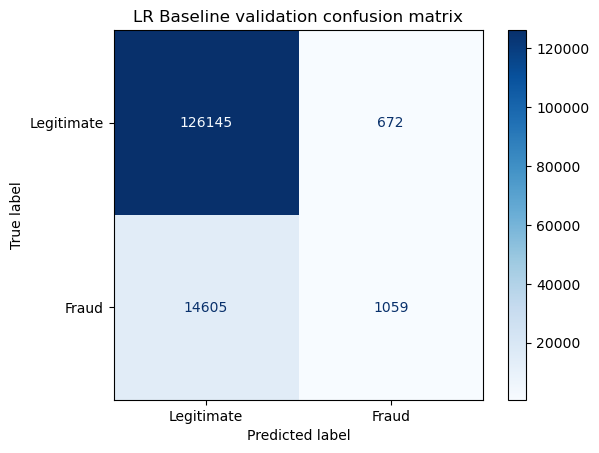

In [22]:
def evaluate_validation(model, version):
    fraud_scores = model.predict_proba(X_val_scaled)[:, 1]
    # Flag orders whose fraud score meets the baseline cutoff.
    predictions = fraud_scores >= threshold
    metrics = pd.Series(
        {
            "Recall": recall_score(y_val, predictions, zero_division=0),
            "F1 score": f1_score(y_val, predictions, zero_division=0),
            "Precision": precision_score(y_val, predictions, zero_division=0),
            "Accuracy": accuracy_score(y_val, predictions),
        },
        name=version,
    )
    # Show legitimate orders first and fraud second.
    matrix = confusion_matrix(y_val, predictions, labels=[0, 1])
    display(metrics.to_frame().T.round(4))
    chart = ConfusionMatrixDisplay(matrix, display_labels=["Legitimate", "Fraud"])
    chart.plot(cmap="Blues", values_format="d")
    chart.ax_.set_title(f"{version} validation confusion matrix")
    plt.show()
    plt.close(chart.figure_)
    return metrics, matrix


baseline_metrics, baseline_matrix = evaluate_validation(baseline, "LR Baseline")

### Baseline Results and Proposed Improvement
At the 0.50 cutoff, the baseline correctly classified 126,145 legitimate orders and incorrectly flagged 672. It caught 1,059 fraudulent orders and missed 14,605. Fraud made up only 10.99% of the validation set, so correctly classifying legitimate orders drove the overall accuracy of 89.28%. The confusion matrix shows that reducing missed fraud is the main priority.

The proposed improvement is to tune the class weights using class_weight="balanced", which gives fraudulent orders more weight during training. This may reduce missed fraud while increasing false alarms and lowering overall accuracy. Keeping the same validation orders and cutoff allows a direct comparison of how many additional fraud cases are caught and how many additional legitimate orders are flagged for review.

## 6️⃣ Model Improvement

Use balanced class weights to give fraudulent orders more weight during training. Keep the baseline settings and training data so the comparison isolates the effect of class weighting.

In [23]:
# Keep the baseline settings and change only the class weights.
improved = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
improved.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

## 7️⃣ Improved Model Evaluation

Evaluate the improved model on the same validation orders at the same 0.50 cutoff. Compare recall, F1 score, precision, and accuracy. Use the confusion matrices to check how many more fraud cases were caught and how many more legitimate orders were flagged for review.

,Recall,F1 score,Precision,Accuracy
LR Improved,0.7051,0.3805,0.2606,0.7476


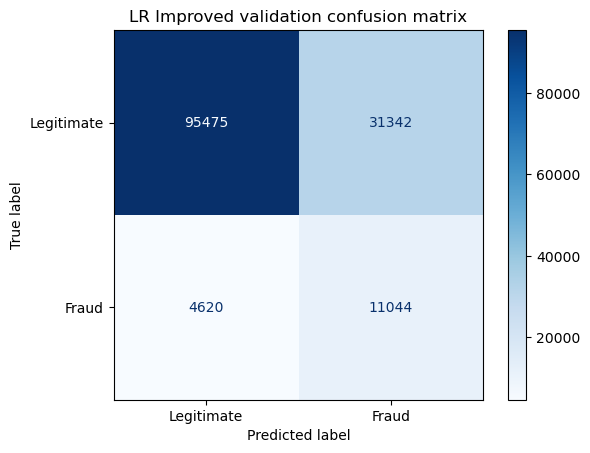

,Recall,F1 score,Precision,Accuracy
LR Baseline,0.0676,0.1218,0.6118,0.8928
LR Improved,0.7051,0.3805,0.2606,0.7476


,Correctly cleared,False alarms,Missed fraud,Fraud caught
LR Baseline,126145,672,14605,1059
LR Improved,95475,31342,4620,11044


In [24]:
improved_metrics, improved_matrix = evaluate_validation(improved, "LR Improved")

# Compare the validation metrics side by side.
display(pd.DataFrame([baseline_metrics, improved_metrics]).round(4))

# Read both confusion matrices in row order using legitimate (0), then fraud (1).
confusion_comparison = pd.DataFrame(
    [baseline_matrix.ravel(), improved_matrix.ravel()],
    index=["LR Baseline", "LR Improved"],
    columns=["Correctly cleared", "False alarms", "Missed fraud", "Fraud caught"],
)
confusion_comparison

### Improved Model Results

At the 0.50 cutoff, balanced class weights increased fraud detections from 1,059 to 11,044 and reduced missed fraud from 14,605 to 4,620. False alarms rose from 672 to 31,342. The model caught substantially more fraud, with a much larger review workload for legitimate orders.

## 8️⃣Model Improvement - Threshold Tuning

At the 0.50 cutoff, the improved model caught 11,044 fraudulent orders and incorrectly flagged 31,342 legitimate orders. Test higher cutoffs on the same validation orders to see how many false alarms can be avoided and how many additional fraud cases would be missed.

Use the scores from the existing improved model. A higher cutoff requires a higher fraud score before an order is flagged for review. Keep the 0.50 result as the reference, and choose a cutoff on validation before using the test set.

In [25]:
# Score the validation orders once and reuse the scores for each cutoff.
improved_scores = improved.predict_proba(X_val_scaled)[:, 1]
threshold_results = []

for cutoff in (0.50, 0.55, 0.60, 0.65, 0.70):
    predictions = improved_scores >= cutoff
    matrix = confusion_matrix(y_val, predictions, labels=[0, 1])
    correctly_cleared, false_alarms, missed_fraud, fraud_caught = matrix.ravel()
    threshold_results.append({
        "Cutoff": cutoff,
        "Correctly cleared": correctly_cleared,
        "False alarms": false_alarms,
        "Missed fraud": missed_fraud,
        "Fraud caught": fraud_caught,
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1 score": f1_score(y_val, predictions, zero_division=0),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Accuracy": accuracy_score(y_val, predictions),
    })

pd.DataFrame(threshold_results).set_index("Cutoff").round(4)

,Correctly cleared,False alarms,Missed fraud,Fraud caught,Recall,F1 score,Precision,Accuracy
Cutoff,,,,,,,,
0.50,95475,31342,4620,11044,0.7051,0.3805,0.2606,0.7476
0.55,100287,26530,5535,10129,0.6466,0.3872,0.2763,0.7750
0.60,104106,22711,6335,9329,0.5956,0.3911,0.2912,0.7961
0.65,107965,18852,7243,8421,0.5376,0.3922,0.3088,0.8169
0.70,112178,14639,8370,7294,0.4657,0.3880,0.3326,0.8385


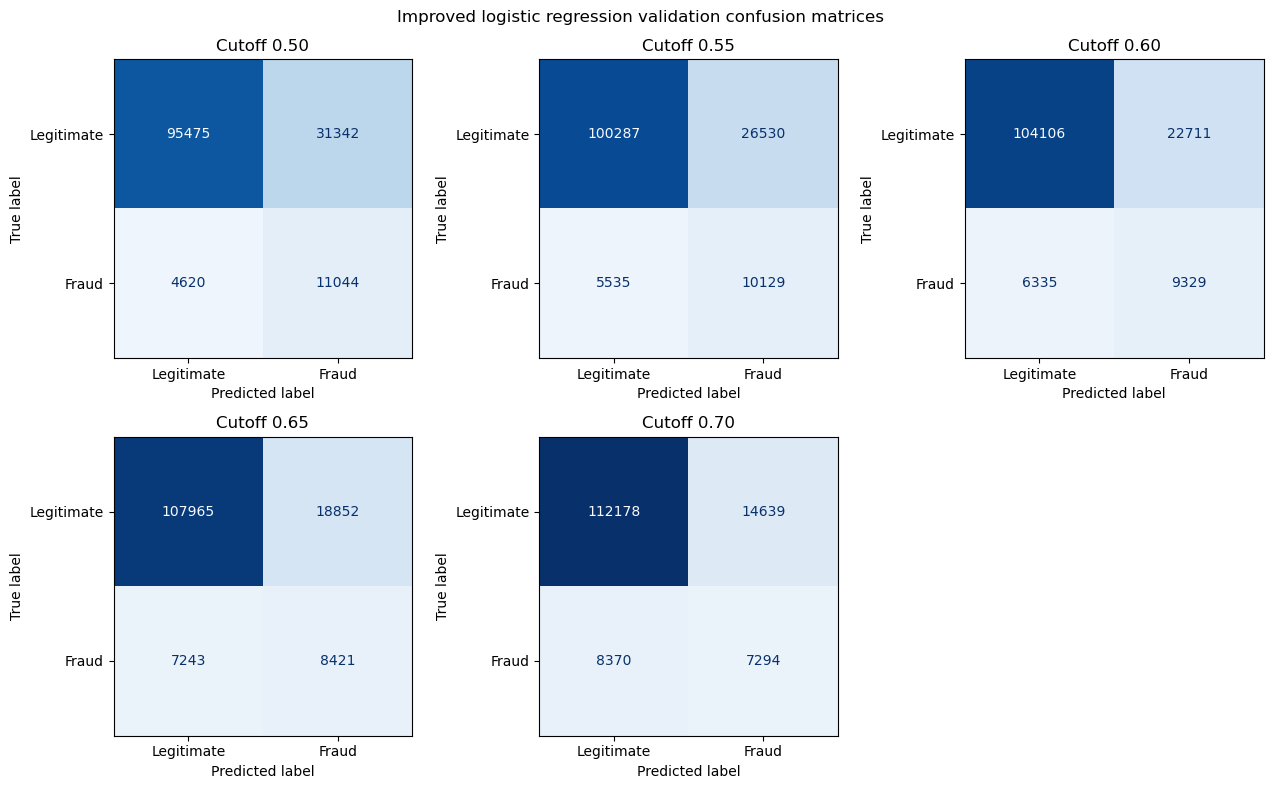

In [27]:
# Plot the validation confusion matrix for each cutoff tested.
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
max_count = max(result["Correctly cleared"] for result in threshold_results)

for ax, result in zip(axes.flat, threshold_results):
    cutoff = result["Cutoff"]
    predictions = improved_scores >= cutoff
    matrix = confusion_matrix(y_val, predictions, labels=[0, 1])
    chart = ConfusionMatrixDisplay(matrix, display_labels=["Legitimate", "Fraud"])
    chart.plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False,
        im_kw={"vmin": 0, "vmax": max_count},
    )
    ax.set_title(f"Cutoff {cutoff:.2f}")

axes.flat[-1].set_visible(False)
fig.suptitle("Improved logistic regression validation confusion matrices")
fig.tight_layout()
plt.show()

### Threshold Tuning Results

At **0.60**, the validation confusion matrix shows **9,329 fraud orders caught**, **6,335 missed**, and **22,711 legitimate orders flagged**. Compared with 0.50, this cutoff avoids **8,631 false alarms** while catching **1,715 fewer fraud orders**.

Compared with 0.65, the 0.60 cutoff catches **908 more fraud orders** and flags **3,859 more legitimate orders**. The selected cutoff of **0.60** prioritises catching those extra fraud cases while still reducing false alarms compared with 0.50.

## 9️⃣Final Test Comparison

Compare both models on the same held-out test orders. Use **0.50** for the baseline and the validation-selected **0.60** cutoff for the improved model.

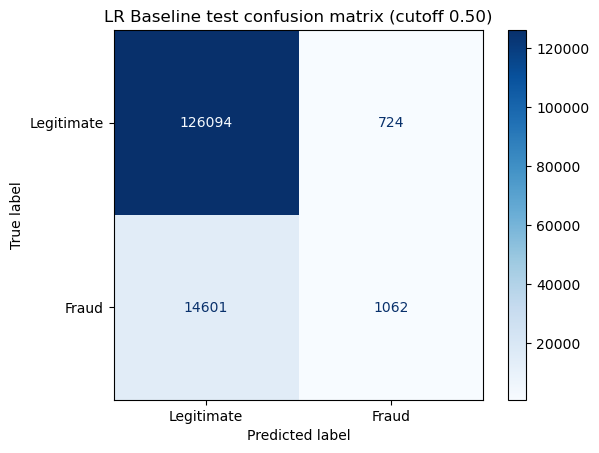

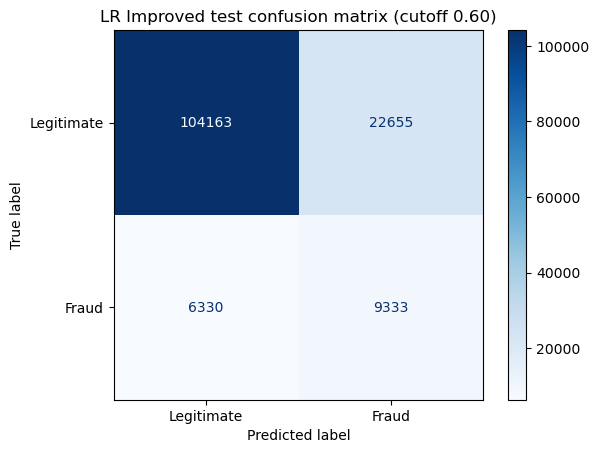

,Cutoff,Correctly cleared,False alarms,Missed fraud,Fraud caught,Recall,F1 score,Precision,Accuracy
Model,,,,,,,,,
LR Baseline,0.5,126094,724,14601,1062,0.0678,0.1217,0.5946,0.8924
LR Improved,0.6,104163,22655,6330,9333,0.5959,0.3917,0.2918,0.7966


In [28]:
# Apply the scaling learned from training to the test features.
X_test_scaled = X_test.copy()
X_test_scaled[numeric_columns] = scaler.transform(X_test[numeric_columns])

test_results = []
test_models = [
    ("LR Baseline", baseline, 0.50),
    ("LR Improved", improved, 0.60),
]

for name, model, cutoff in test_models:
    fraud_scores = model.predict_proba(X_test_scaled)[:, 1]
    predictions = fraud_scores >= cutoff
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    correctly_cleared, false_alarms, missed_fraud, fraud_caught = matrix.ravel()
    test_results.append({
        "Model": name,
        "Cutoff": cutoff,
        "Correctly cleared": correctly_cleared,
        "False alarms": false_alarms,
        "Missed fraud": missed_fraud,
        "Fraud caught": fraud_caught,
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 score": f1_score(y_test, predictions, zero_division=0),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Accuracy": accuracy_score(y_test, predictions),
    })

    chart = ConfusionMatrixDisplay(matrix, display_labels=["Legitimate", "Fraud"])
    chart.plot(cmap="Blues", values_format="d")
    chart.ax_.set_title(f"{name} test confusion matrix (cutoff {cutoff:.2f})")
    plt.show()
    plt.close(chart.figure_)

test_comparison = pd.DataFrame(test_results).set_index("Model")
test_comparison.round(4)